# preQCA v3 — Normalizar las métricas y barrer los umbrales de calibración

QCA necesita representar las condiciones y el resultado como **pertenencias a conjuntos**.

En `preQCA_v2` calibramos las condiciones con un único conjunto de umbrales fijos y, en `Tesis_QCA_v2`, ninguna combinación resultó suficiente para `INCO_ALTO`. En este notebook ampliaremos la exploración en tres direcciones:

1. **Usaremos toda la información disponible.** Partiremos de la nueva `base_completa`, que contiene las métricas de red de los gobiernos regionales para todos los años de contratación, de 2004 a 2024.
2. **Normalizaremos las métricas de red entre 0 y 1.** Así las diferencias entre gobiernos regionales quedarán expresadas en una escala común, en la que se pueden comparar y expandir.
3. **Haremos un barrido de umbrales.** En lugar de fijar un único conjunto de anclajes por condición, iremos bajando poco a poco el punto de cruce y observaremos en qué momento cada condición empieza a asociarse con `INCO_ALTO`.

Las condiciones y el resultado serán los mismos de `preQCA_v2`: `ALCANCE`, `COMPARTIDAS`, `CONCENTRACION` y `PERSISTENCIA`, y el resultado `INCO_ALTO`.

**Unidad de análisis:** cada gobierno regional en un año determinado (GORE–año).

`mediciones originales → normalización → umbrales → barrido de calibraciones → diagnóstico → membresías`

In [1]:
!pip -q install setqca

"pip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


## preQCA-01: conocer las mediciones originales

Cada fila representa un **gobierno regional en un año determinado (GORE–año)**.

La nueva base contiene los 25 gobiernos regionales para cada año entre 2004 y 2024: 25 × 21 = 525 filas. Las métricas de las redes de contratación todavía son **mediciones empíricas**, no membresías QCA.

In [2]:
import pandas as pd
import numpy as np

linkGit = "https://raw.githubusercontent.com/romloayza/networks_x_qca_tesis/refs/heads/main/v2/data/base_completa.csv"

base = pd.read_csv(linkGit)

print("Filas:", len(base), "| GORE:", base["GORE"].nunique(), "| años:", base["AÑO"].min(), "a", base["AÑO"].max())
base.head()

Filas: 525 | GORE: 25 | años: 2004 a 2024


,GORE,AÑO,n_contratos,monto_total,grado,grado_ponderado,centralidad_grado,centralidad_intermediacion,centralidad_cercania_armonica,centralidad_eigenvector,...,tasa_recurrencia,pct_contratos_consorcio,empresas_por_contrato,emp_n_aristas,emp_densidad,emp_grado_promedio,emp_clustering,emp_n_componentes,emp_pct_componente_mayor,INCO
0,AMAZONAS,2004,0,0.0,0,0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
1,AMAZONAS,2005,0,0.0,0,0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
2,AMAZONAS,2006,0,0.0,0,0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
3,AMAZONAS,2007,0,0.0,0,0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN
4,AMAZONAS,2008,0,0.0,0,0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN


Antes de calibrar, observaremos cuántos gobiernos regionales contrataron obras en cada año y en qué años disponemos del INCO.

Un GORE–año **con contratos** es aquel que adjudicó al menos un contrato de obra en el año (`n_contratos > 0`). Cuando un GORE no contrató en un año, su red no existe: sus conteos valen 0 y sus proporciones quedan vacías.

In [3]:
cobertura_anios = base.groupby("AÑO").agg(
    GORE_con_contratos=("n_contratos", lambda s: int((s > 0).sum())),
    GORE_con_INCO=("INCO", lambda s: int(s.notna().sum()))
)

with pd.option_context("display.max_columns", None):
    display(cobertura_anios.T)

AÑO,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
GORE_con_contratos,1,10,13,18,18,18,21,21,24,24,20,22,24,24,24,24,24,23,24,22,22
GORE_con_INCO,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,25,25,0,25


### ¿Cómo leer el resultado?

Las métricas de red cubren los 21 años, aunque en los primeros pocos gobiernos regionales registran contratos: en 2004 solo Lima y en 2005 diez gobiernos regionales.

El INCO, en cambio, solo está disponible para 2021, 2022 y 2024. Como QCA necesita conocer el resultado de cada caso, **los casos del análisis seguirán siendo los GORE–año con INCO**. Los demás años no entran como casos, pero sí aportan información: los utilizaremos para definir la escala de normalización de las métricas de red (preQCA-02), de modo que cada GORE–año se compare con todo lo observado entre 2004 y 2024 y no solo con los tres años del INCO.

Además, la `tasa_recurrencia` ya incorpora la historia: mide la proporción de empresas del año que habían contratado con el mismo GORE en algún año anterior desde 2004.

In [4]:
METRICAS = {
    "ALCANCE": "grado",
    "COMPARTIDAS": "pct_empresas_compartidas",
    "CONCENTRACION": "hhi_monto",
    "PERSISTENCIA": "tasa_recurrencia"
}

qca_raw = base[["GORE", "AÑO", "n_contratos"] + list(METRICAS.values()) + ["INCO"]].copy()

qca_raw.head()

,GORE,AÑO,n_contratos,grado,pct_empresas_compartidas,hhi_monto,tasa_recurrencia,INCO
0,AMAZONAS,2004,0,0,NaN,NaN,NaN,NaN
1,AMAZONAS,2005,0,0,NaN,NaN,NaN,NaN
2,AMAZONAS,2006,0,0,NaN,NaN,NaN,NaN
3,AMAZONAS,2007,0,0,NaN,NaN,NaN,NaN
4,AMAZONAS,2008,0,0,NaN,NaN,NaN,NaN


## De las mediciones a los conjuntos

A partir de las mediciones originales construiremos cinco conjuntos: cuatro condiciones y un resultado.

- `ALCANCE`: GORE–año con alta centralidad de grado en la red bipartita de contratación, medida como el número de empresas contratistas distintas con las que contrata en el año (`grado`).
- `COMPARTIDAS`: GORE–año con alta proporción de empresas contratistas compartidas con otros gobiernos regionales en el mismo año (`pct_empresas_compartidas`).
- `CONCENTRACION`: GORE–año con alta concentración del monto contratado entre sus empresas contratistas, medida mediante el HHI de montos (`hhi_monto`).
- `PERSISTENCIA`: GORE–año con alta proporción de empresas contratistas que ya habían contratado con el mismo gobierno regional en años anteriores (`tasa_recurrencia`).
- `INCO_ALTO`: GORE–año con alto puntaje de riesgo de corrupción e inconducta funcional según el INCO, en relación con los demás gobiernos regionales del mismo año.

Los cuatro primeros conjuntos representan las condiciones y el último representa el resultado.

La medición original y el conjunto no son lo mismo. Aunque normalicemos las métricas entre 0 y 1, sus valores normalizados **tampoco son membresías QCA**: la normalización solo cambia la escala de la medición. La calibración seguirá siendo el paso que traduce cada medición en un grado de pertenencia al conjunto.

## preQCA-02: normalizar las métricas de red entre 0 y 1

Las cuatro métricas de red están expresadas en escalas distintas: `grado` es un conteo de empresas (de 1 a más de 100), mientras que las otras tres son proporciones. Además, muchos valores se concentran en rangos estrechos, por lo que dos GORE–año pueden parecer casi iguales aunque ocupen posiciones distintas dentro de la distribución.

Utilizaremos la **normalización min–max**:

$$x_{norm} = \frac{x - \min(x)}{\max(x) - \min(x)}$$

Con ella, el menor valor observado pasa a 0, el mayor a 1 y los demás se ubican proporcionalmente entre ambos. Así todas las condiciones quedan en la misma escala de 0 a 1 y podremos barrer sus umbrales con una misma grilla.

El mínimo y el máximo se calcularán con **todos los GORE–año con contratos entre 2004 y 2024**, no solo con los casos que tienen INCO. Excluimos los GORE–año sin contratos porque en ellos no existe una red: su `grado` igual a 0 no es una medición del alcance, sino la ausencia de contratación, y fijaría artificialmente el mínimo.

El INCO **no se normaliza**: conservará los anclajes por año utilizados en `preQCA_v2`.

In [5]:
activos = qca_raw[qca_raw["n_contratos"] > 0]

escala = pd.DataFrame({
    "mínimo": activos[list(METRICAS.values())].min(),
    "máximo": activos[list(METRICAS.values())].max()
})

print("GORE–año con contratos utilizados para la escala:", len(activos))
escala

GORE–año con contratos utilizados para la escala: 421


,mínimo,máximo
grado,1.000000,142.0
pct_empresas_compartidas,0.000000,1.0
hhi_monto,0.013062,1.0
tasa_recurrencia,0.000000,1.0


Ahora aplicamos la normalización a los casos del análisis: los GORE–año con INCO y con todas las métricas de red disponibles. Conservaremos las mediciones originales y crearemos nuevas columnas terminadas en `_norm`.

In [6]:
qca_datos = qca_raw.dropna(subset=list(METRICAS.values()) + ["INCO"]).reset_index(drop=True)

for columna in METRICAS.values():
    qca_datos[columna + "_norm"] = (
        (qca_datos[columna] - escala.loc[columna, "mínimo"])
        / (escala.loc[columna, "máximo"] - escala.loc[columna, "mínimo"])
    )

print("Casos del análisis:", len(qca_datos))

comparacion_norm = pd.concat({
    "original": qca_datos[list(METRICAS.values())].describe().loc[["min", "25%", "50%", "75%", "max"]],
    "normalizada": qca_datos[[c + "_norm" for c in METRICAS.values()]]
        .rename(columns=lambda c: c.replace("_norm", ""))
        .describe().loc[["min", "25%", "50%", "75%", "max"]]
}, axis=1).round(3)

comparacion_norm

Casos del análisis: 69


original                                                     normalizada  \
       grado pct_empresas_compartidas hhi_monto tasa_recurrencia       grado   
min      2.0                    0.000     0.015            0.000       0.007   
25%     10.0                    0.111     0.108            0.238       0.064   
50%     18.0                    0.182     0.158            0.390       0.121   
75%     32.0                    0.267     0.291            0.464       0.220   
max    142.0                    1.000     0.777            1.000       1.000   

                                                         
    pct_empresas_compartidas hhi_monto tasa_recurrencia  
min                    0.000     0.002            0.000  
25%                    0.111     0.096            0.238  
50%                    0.182     0.146            0.390  
75%                    0.267     0.282            0.464  
max                    1.000     0.774            1.000

### ¿Cómo leer el resultado?

Los casos del análisis son 69 GORE–año. Los 6 GORE–año restantes con INCO no contrataron obras en su año, por lo que sus métricas de red no existen y no pueden calibrarse.

La normalización modifica principalmente dos métricas:

- `grado` pasa de una escala de 1 a 142 empresas a una escala de 0 a 1. El máximo corresponde a Áncash 2022, con 142 empresas contratistas. Como pocos GORE–año contratan con tantas empresas, la mitad de los casos queda por debajo de 0.12.
- `hhi_monto` se estira levemente, porque su mínimo histórico (0.013) es mayor que 0 y su máximo es 1.

`pct_empresas_compartidas` y `tasa_recurrencia` **prácticamente no cambian**: entre 2004 y 2024 ya existen GORE–año con valores de 0 y de 1, de modo que la escala histórica coincide con la escala original.

Como la mayoría de los casos se ubica en la parte baja de la escala normalizada, el barrido de umbrales deberá llegar a puntos de cruce bajos para que haya casos dentro de los conjuntos.

## preQCA-03: calibrar el resultado `INCO_ALTO`

Mantendremos la calibración del resultado utilizada en `preQCA_v2`. Los anclajes se definen dentro de cada año:

| Anclaje | Valor |
|---|---|
| Fuera (`full_out`) | puntaje del 5.º GORE con menor INCO del año |
| Cruce (`crossover`) | punto medio entre ambos |
| Dentro (`full_in`) | puntaje del 5.º GORE con mayor INCO del año |

Así se evita que el descenso del INCO entre 2021 y 2024 se confunda con diferencias entre gobiernos regionales. Los anclajes se calculan con los 25 GORE de cada año, incluidos los que no contrataron obras.

Para evaluar la sensibilidad de los resultados en `Tesis_QCA` conservaremos también `INCO_ALTO_ORIGINAL` (30, 50 y 70) e `INCO_ALTO_FIJO` (60, 70 y 80).

El resultado **no forma parte del barrido**: solo moveremos los umbrales de las condiciones, para que los cambios observados se deban a ellas.

In [7]:
from setqca import calibrate_direct

anclajes_inco = {}
for anio, grupo in qca_raw.dropna(subset=["INCO"]).groupby("AÑO"):
    puntajes = grupo["INCO"].sort_values().values
    fuera, dentro = puntajes[4], puntajes[-5]
    anclajes_inco[anio] = (fuera, round((fuera + dentro) / 2, 2), dentro)

INCO_ALTO = pd.Series(np.nan, index=qca_datos.index)
for anio, (fuera, cruce, dentro) in anclajes_inco.items():
    filas = qca_datos["AÑO"] == anio
    INCO_ALTO[filas] = calibrate_direct(
        qca_datos.loc[filas, "INCO"],
        full_out=fuera,
        crossover=cruce,
        full_in=dentro
    )

INCO_ALTO_ORIGINAL = calibrate_direct(qca_datos["INCO"], full_out=30, crossover=50, full_in=70)
INCO_ALTO_FIJO = calibrate_direct(qca_datos["INCO"], full_out=60, crossover=70, full_in=80)

print("Anclajes por año:", {a: tuple(float(v) for v in t) for a, t in anclajes_inco.items()})
print("Casos dentro de INCO_ALTO (> 0.5):", int((INCO_ALTO > 0.5).sum()), "de", len(INCO_ALTO))
casos_inco_05 = qca_datos.loc[np.isclose(INCO_ALTO, 0.5)]
print("Casos con INCO_ALTO = 0.5:", (casos_inco_05["GORE"] + "_" + casos_inco_05["AÑO"].astype(str)).tolist())

Anclajes por año: {2021: (68.3, 78.6, 88.9), 2022: (67.3, 73.85, 80.4), 2024: (56.1, 62.0, 67.9)}
Casos dentro de INCO_ALTO (> 0.5): 31 de 69
Casos con INCO_ALTO = 0.5: ['TUMBES_2024']


## preQCA-04: definir el barrido de umbrales

En `preQCA_v2` cada condición tenía tres anclajes fijos (fuera, cruce y dentro). El problema es que, si la relación con el resultado aparece con otros umbrales, un único conjunto de anclajes no permite advertirlo.

Un **barrido de umbrales** consiste en repetir la calibración muchas veces, cambiando poco a poco los anclajes, y registrar qué ocurre en cada repetición. En nuestro caso:

- el **cruce** de cada condición irá **bajando de 0.90 a 0.10, en pasos de 0.05**, sobre la escala normalizada;
- el anclaje **fuera** se ubicará 0.15 por debajo del cruce y el anclaje **dentro** 0.15 por encima, sin salir del rango de 0 a 1.

Con un cruce alto, solo los GORE–año con valores muy altos de la métrica pertenecen al conjunto; a medida que el cruce baja, más casos ingresan. Obtendremos 17 calibraciones por condición y 68 en total.

El barrido se hace **condición por condición**, porque la membresía en un conjunto depende solo de sus propios umbrales: la membresía en `ALCANCE` no cambia si movemos los umbrales de `CONCENTRACION`. Las **combinaciones** entre condiciones se evaluarán después, en `Tesis_QCA`, mediante la tabla de verdad.

In [8]:
PASO_CRUCE = 0.05
DISTANCIA_ANCLAJES = 0.15

cruces = np.round(np.arange(0.90, 0.10 - 1e-9, -PASO_CRUCE), 2)

grilla = pd.DataFrame({
    "cruce": cruces,
    "fuera": np.round(np.maximum(cruces - DISTANCIA_ANCLAJES, 0), 2),
    "dentro": np.round(np.minimum(cruces + DISTANCIA_ANCLAJES, 1), 2)
})

print("Calibraciones por condición:", len(grilla), "| total:", len(grilla) * len(METRICAS))
grilla.T

Calibraciones por condición: 17 | total: 68


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
cruce,0.90,0.85,0.80,0.75,0.70,0.65,0.60,0.55,0.50,0.45,0.40,0.35,0.30,0.25,0.20,0.15,0.10
fuera,0.75,0.70,0.65,0.60,0.55,0.50,0.45,0.40,0.35,0.30,0.25,0.20,0.15,0.10,0.05,0.00,0.00
dentro,1.00,1.00,0.95,0.90,0.85,0.80,0.75,0.70,0.65,0.60,0.55,0.50,0.45,0.40,0.35,0.30,0.25


## preQCA-05: calibrar cada condición con todos los umbrales

Ahora recorremos la grilla con un *loop*: para cada condición y cada fila de la grilla aplicamos `calibrate_direct()` sobre la métrica normalizada.

Cada calibración genera una columna de membresías con el nombre de la condición y su cruce. Por ejemplo, `ALCANCE_c0.50` contiene las membresías en `ALCANCE` cuando el cruce es 0.50. Todas se guardan en la tabla `barrido`, junto con el caso y `INCO_ALTO`.

In [9]:
barrido = pd.DataFrame({
    "caso": qca_datos["GORE"] + "_" + qca_datos["AÑO"].astype(str),
    "AÑO": qca_datos["AÑO"],
    "INCO": qca_datos["INCO"],
    "INCO_ALTO": INCO_ALTO
})

columnas_barrido = {}
for conjunto, columna in METRICAS.items():
    for _, umbral in grilla.iterrows():
        nombre = f"{conjunto}_c{umbral['cruce']:.2f}"
        columnas_barrido[nombre] = calibrate_direct(
            qca_datos[columna + "_norm"],
            full_out=umbral["fuera"],
            crossover=umbral["cruce"],
            full_in=umbral["dentro"]
        )

barrido = pd.concat([barrido, pd.DataFrame(columnas_barrido)], axis=1)

print("Columnas de membresías generadas:", len(columnas_barrido))
barrido[["caso", "INCO_ALTO", "ALCANCE_c0.90", "ALCANCE_c0.50", "ALCANCE_c0.10"]].head()

Columnas de membresías generadas: 68


,caso,INCO_ALTO,ALCANCE_c0.90,ALCANCE_c0.50,ALCANCE_c0.10
0,AMAZONAS_2021,0.050000,9.118626e-07,0.002338,0.857649
1,AMAZONAS_2022,0.047907,4.545941e-07,0.001167,0.750225
2,AMAZONAS_2024,0.001520,3.192118e-06,0.008138,0.954733
3,ANCASH_2021,0.950000,8.359179e-04,0.682589,0.999819
4,ANCASH_2022,0.990124,9.500000e-01,0.999945,1.000000


### ¿Cómo leer el resultado?

Para un mismo caso, la membresía aumenta a medida que el cruce baja. Por ejemplo, un GORE–año con pocas empresas contratistas queda fuera de `ALCANCE` con un cruce de 0.90 o 0.50, pero puede quedar dentro cuando el cruce desciende a 0.10. El barrido permite ver ese tránsito completo en lugar de una sola fotografía.

## preQCA-06: diagnosticar cada calibración

Para decidir qué calibraciones merecen ser llevadas a `Tesis_QCA`, calcularemos para cada una de las 68 calibraciones dos tipos de información.

**1. Distribución de los casos**

- `casos_dentro`: GORE–año con membresía superior a 0.5;
- `casos_fuera`: GORE–año con membresía inferior a 0.5;
- `casos_en_0.5`: GORE–año con membresía exactamente igual a 0.5, en el punto de máxima ambigüedad.

Un conjunto en el que casi todos los casos están dentro, o casi todos fuera, es poco informativo: no distingue entre gobiernos regionales.

**2. Relación de la condición, por sí sola, con `INCO_ALTO`**

Utilizaremos `sufficiency()` de `setqca`, que calcula para una condición:

- **consistencia**: en qué medida la membresía en la condición es un subconjunto de la membresía en `INCO_ALTO`, es decir, hasta qué punto los GORE–año que pertenecen a la condición también pertenecen al resultado;
- **cobertura**: qué parte de la membresía en `INCO_ALTO` queda cubierta por la condición;
- **PRI**: cuánto de esa consistencia corresponde a `INCO_ALTO` y no simultáneamente a `~INCO_ALTO`.

Calcularemos estas medidas para la presencia de la condición y para su ausencia (`~`), porque en QCA las relaciones son asimétricas.

Estas medidas evalúan **cada condición aislada**. No reemplazan la tabla de verdad ni la minimización de `Tesis_QCA`, pero muestran en qué rango de umbrales cada condición empieza a asociarse con el resultado.

In [10]:
from setqca import sufficiency

filas_diagnostico = []
for conjunto in METRICAS:
    for _, umbral in grilla.iterrows():
        membresia = barrido[f"{conjunto}_c{umbral['cruce']:.2f}"]
        presencia = sufficiency(membresia, barrido["INCO_ALTO"])
        ausencia = sufficiency(1 - membresia, barrido["INCO_ALTO"])
        filas_diagnostico.append({
            "condicion": conjunto,
            "cruce": umbral["cruce"],
            "fuera": umbral["fuera"],
            "dentro": umbral["dentro"],
            "casos_dentro": int((membresia > 0.5).sum()),
            "casos_fuera": int((membresia < 0.5).sum()),
            "casos_en_0.5": int(np.isclose(membresia, 0.5).sum()),
            "consistencia": presencia.consistency,
            "cobertura": presencia.coverage,
            "PRI": presencia.pri,
            "consistencia_ausencia": ausencia.consistency,
            "cobertura_ausencia": ausencia.coverage,
            "PRI_ausencia": ausencia.pri
        })

diagnostico = pd.DataFrame(filas_diagnostico)

with pd.option_context("display.max_rows", None):
    display(diagnostico.drop(columns=["fuera", "dentro"]).round(3))

,condicion,cruce,casos_dentro,casos_fuera,casos_en_0.5,consistencia,cobertura,PRI,consistencia_ausencia,cobertura_ausencia,PRI_ausencia
0,ALCANCE,0.90,1,68,0,1.000,0.034,1.000,0.454,0.967,0.344
1,ALCANCE,0.85,1,68,0,1.000,0.039,1.000,0.453,0.962,0.342
2,ALCANCE,0.80,2,67,0,1.000,0.047,1.000,0.451,0.954,0.339
3,ALCANCE,0.75,2,67,0,0.999,0.056,0.999,0.449,0.946,0.336
4,ALCANCE,0.70,2,67,0,0.996,0.063,0.996,0.449,0.942,0.335
5,ALCANCE,0.65,2,67,0,0.996,0.071,0.996,0.449,0.938,0.335
6,ALCANCE,0.60,2,67,0,0.996,0.085,0.995,0.449,0.932,0.334
7,ALCANCE,0.55,3,66,0,0.995,0.109,0.994,0.446,0.915,0.328
8,ALCANCE,0.50,4,65,0,0.937,0.134,0.918,0.443,0.894,0.324
9,ALCANCE,0.45,5,64,0,0.866,0.161,0.822,0.443,0.876,0.324


### ¿Cómo leer el resultado?

Leeremos la tabla de arriba hacia abajo dentro de cada condición, es decir, a medida que el cruce baja.

- **`ALCANCE`** es la única condición que alcanza consistencias altas. Con cruces de 0.55 o más, la consistencia es cercana a 1, pero solo 1 a 3 GORE–año están dentro del conjunto y la cobertura no supera 0.11: son pocos gobiernos regionales con un número muy alto de contratistas que, además, tienen INCO alto en su año. Con un cruce de 0.50 la consistencia es 0.937 (4 casos dentro) y con 0.45 es 0.866 (5 casos), todavía por encima de 0.80. Desde 0.40 cae por debajo de 0.80 y sigue bajando a medida que ingresan más casos.
- **`COMPARTIDAS`** alcanza su mayor consistencia alrededor de cruces de 0.50 a 0.55 (0.75), con solo 3 casos dentro. Su ausencia, `~COMPARTIDAS`, gana consistencia a medida que el cruce baja, pero porque cada vez menos casos quedan fuera.
- **`CONCENTRACION`** se mantiene entre 0.62 y 0.66 en la mayor parte de los cruces intermedios (de 0.55 a 0.25), sin superar 0.80.
- **`PERSISTENCIA`** se mantiene entre 0.59 y 0.67 en los cruces altos e intermedios y desciende cuando el cruce baja de 0.45.

Por tanto, el barrido sugiere que **la relación más fuerte aparece en el extremo alto de `ALCANCE`**: los GORE–año con un número de contratistas muy superior al resto. Es una relación que involucra a pocos casos, por lo que a continuación veremos qué gobiernos regionales son y, en `Tesis_QCA`, convendrá examinar si la relación se mantiene al combinar `ALCANCE` con las demás condiciones.

In [11]:
# GORE–año dentro de ALCANCE con los cruces en los que su consistencia cruza 0.80
casos_alcance = barrido.loc[
    barrido["ALCANCE_c0.40"] > 0.5,
    ["caso", "INCO", "INCO_ALTO", "ALCANCE_c0.45", "ALCANCE_c0.40"]
]

casos_alcance.round(3)

,caso,INCO,INCO_ALTO,ALCANCE_c0.45,ALCANCE_c0.40
3,ANCASH_2021,88.9,0.950,0.852,0.939
4,ANCASH_2022,84.1,0.990,1.000,1.000
28,HUANUCO_2024,58.2,0.131,0.416,0.655
34,JUNIN_2024,71.6,0.992,0.999,1.000
43,LIMA_2024,63.2,0.645,0.897,0.959
46,LORETO_2024,67.9,0.950,0.653,0.834
50,PASCO_2024,61.4,0.426,0.416,0.655


### ¿Cómo leer el resultado?

Con un cruce de 0.45, los cinco GORE–año dentro de `ALCANCE` son Áncash 2021, Áncash 2022, Junín 2024, Lima 2024 y Loreto 2024, y todos tienen una membresía superior a 0.5 en `INCO_ALTO`. Por eso la consistencia es alta.

Al bajar el cruce a 0.40 ingresan Huánuco 2024 y Pasco 2024, que tienen un INCO relativamente bajo en su año (`INCO_ALTO` < 0.5), y la consistencia cae por debajo de 0.80. El punto en el que la relación deja de sostenerse se ubica, por tanto, entre los cruces de 0.45 y 0.40 de `ALCANCE`, es decir, alrededor de 57 a 64 empresas contratistas en el año.

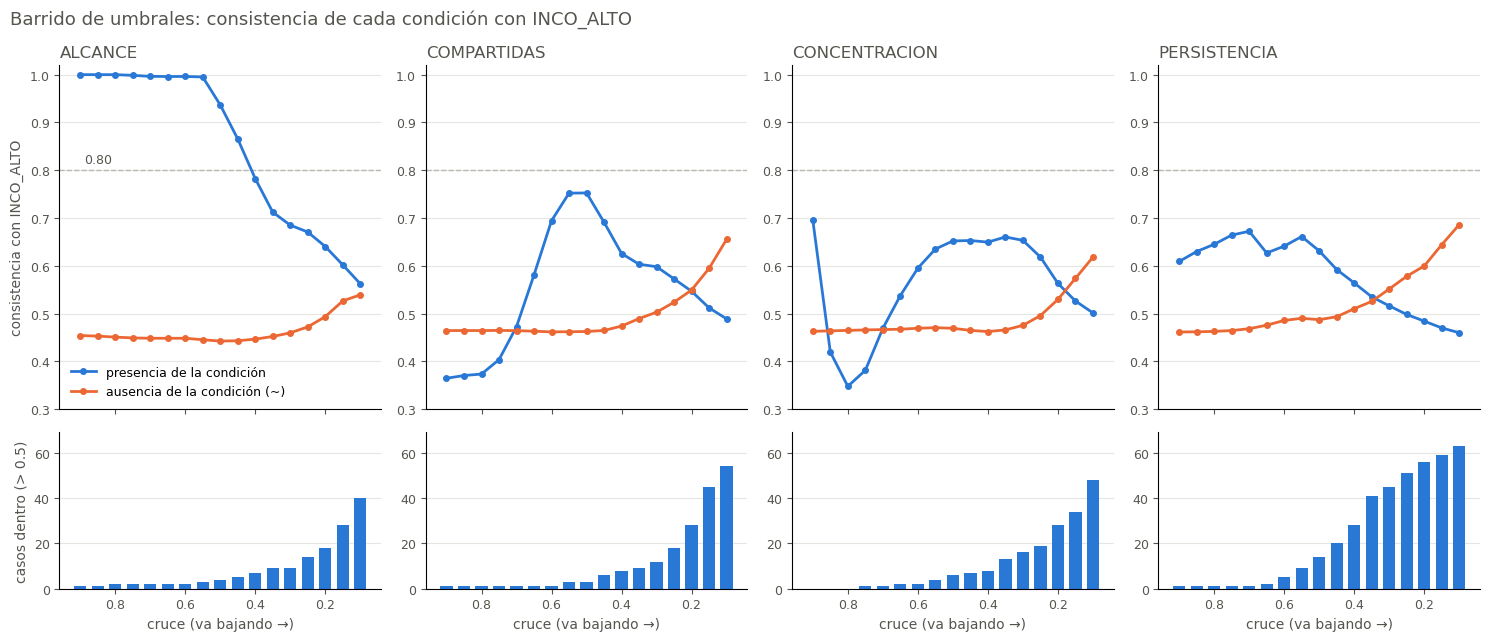

In [12]:
import matplotlib.pyplot as plt

AZUL, NARANJA, GRIS, TEXTO = "#2a78d6", "#eb6834", "#b8b8b0", "#55554f"

fig, ejes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1]})

for j, conjunto in enumerate(METRICAS):
    d = diagnostico[diagnostico["condicion"] == conjunto]
    arriba, abajo = ejes[0, j], ejes[1, j]

    arriba.axhline(0.80, color=GRIS, linestyle="--", linewidth=1)
    arriba.plot(d["cruce"], d["consistencia"], color=AZUL, linewidth=2, marker="o", markersize=4,
                label="presencia de la condición")
    arriba.plot(d["cruce"], d["consistencia_ausencia"], color=NARANJA, linewidth=2, marker="o", markersize=4,
                label="ausencia de la condición (~)")
    arriba.set_title(conjunto, color=TEXTO, fontsize=12, loc="left")
    arriba.set_ylim(0.3, 1.02)

    abajo.bar(d["cruce"], d["casos_dentro"], width=0.035, color=AZUL)
    abajo.set_ylim(0, len(barrido))

    for eje in (arriba, abajo):
        eje.spines[["top", "right"]].set_visible(False)
        eje.tick_params(colors=TEXTO, labelsize=9)
        eje.grid(axis="y", color="#e6e6e1", linewidth=0.8)
        eje.set_axisbelow(True)
    abajo.set_xlabel("cruce (va bajando →)", color=TEXTO)

ejes[0, 0].invert_xaxis()  # los ejes son compartidos: invertir una sola vez

ejes[0, 0].set_ylabel("consistencia con INCO_ALTO", color=TEXTO)
ejes[1, 0].set_ylabel("casos dentro (> 0.5)", color=TEXTO)
ejes[0, 0].text(0.89, 0.815, "0.80", color=TEXTO, fontsize=9)
ejes[0, 0].legend(frameon=False, fontsize=9, loc="lower left")

fig.suptitle("Barrido de umbrales: consistencia de cada condición con INCO_ALTO", color=TEXTO, x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

### ¿Cómo leer el gráfico?

Cada columna corresponde a una condición y el eje horizontal muestra el cruce, que **baja de izquierda a derecha**.

- En la fila superior, la línea azul es la consistencia de la presencia de la condición con `INCO_ALTO` y la naranja la de su ausencia. La línea discontinua marca 0.80, la consistencia mínima utilizada en `Tesis_QCA`.
- En la fila inferior, las barras muestran cuántos GORE–año quedan dentro del conjunto con cada cruce.

Leer ambas filas juntas es importante: una consistencia alta con muy pocos casos dentro, como la de `ALCANCE` con cruces altos, indica una relación que vale solo para unos pocos GORE–año. A medida que el cruce baja ingresan más casos y la consistencia tiende a disminuir, porque el conjunto empieza a incluir gobiernos regionales con INCO alto y bajo.

## preQCA-07: elegir una calibración principal

`Tesis_QCA` necesita una base con una sola membresía por condición. Para construirla elegiremos, para cada condición, un cruce del barrido con un criterio explícito:

1. **Evitar conjuntos muy sesgados.** Solo consideramos los cruces en los que entre el 15 % y el 85 % de los casos quedan dentro del conjunto. Un conjunto con casi todos los casos dentro o fuera no distingue entre gobiernos regionales y produce relaciones triviales.
2. **Entre esos cruces, elegir el de mayor consistencia** de la presencia de la condición con `INCO_ALTO`.

Este criterio es **exploratorio**: busca la calibración en la que cada condición se asocia más con el resultado sin quedar reducida a pocos casos. Por eso conservaremos todas las calibraciones del barrido en `barrido_calibraciones.csv`, y el diccionario `CRUCE_ELEGIDO` puede modificarse manualmente para probar otras combinaciones.

In [13]:
MIN_DENTRO, MAX_DENTRO = 0.15, 0.85

candidatos = diagnostico[
    diagnostico["casos_dentro"].between(MIN_DENTRO * len(barrido), MAX_DENTRO * len(barrido))
]

elegidos = candidatos.loc[candidatos.groupby("condicion")["consistencia"].idxmax()]
CRUCE_ELEGIDO = dict(zip(elegidos["condicion"], elegidos["cruce"]))

# Para probar otra combinación, reemplazar los valores, por ejemplo:
# CRUCE_ELEGIDO = {"ALCANCE": 0.45, "COMPARTIDAS": 0.30, "CONCENTRACION": 0.35, "PERSISTENCIA": 0.50}

print("Cruce elegido por condición:", CRUCE_ELEGIDO)
elegidos.set_index("condicion").loc[list(METRICAS)][
    ["cruce", "fuera", "dentro", "casos_dentro", "casos_en_0.5", "consistencia", "cobertura", "PRI"]
].round(3)

Cruce elegido por condición: {'ALCANCE': 0.25, 'COMPARTIDAS': 0.3, 'CONCENTRACION': 0.35, 'PERSISTENCIA': 0.5}


,cruce,fuera,dentro,casos_dentro,casos_en_0.5,consistencia,cobertura,PRI
condicion,,,,,,,,
ALCANCE,0.25,0.10,0.40,14,0,0.671,0.356,0.521
COMPARTIDAS,0.30,0.15,0.45,12,2,0.598,0.316,0.395
CONCENTRACION,0.35,0.20,0.50,13,0,0.660,0.280,0.516
PERSISTENCIA,0.50,0.35,0.65,14,2,0.631,0.331,0.448


### ¿Cómo leer el resultado?

Con el criterio de 15 % a 85 % de casos dentro, ninguna condición supera por sí sola una consistencia de 0.80. Los cruces elegidos son 0.25 para `ALCANCE`, 0.30 para `COMPARTIDAS`, 0.35 para `CONCENTRACION` y 0.50 para `PERSISTENCIA`, con consistencias entre 0.60 y 0.67.

Esto no significa que no existan combinaciones suficientes: una combinación de condiciones puede ser más consistente que cada condición por separado. Eso es precisamente lo que examinará la tabla de verdad en `Tesis_QCA`.

Ahora construiremos la base calibrada con los cruces elegidos, con el mismo formato que `qca_calibrada_v2.csv`, y compararemos las mediciones con las membresías.

In [14]:
qca = pd.DataFrame({
    "caso": barrido["caso"],
    "AÑO": barrido["AÑO"],
    **{conjunto: barrido[f"{conjunto}_c{CRUCE_ELEGIDO[conjunto]:.2f}"] for conjunto in METRICAS},
    "INCO_ALTO": INCO_ALTO,
    "INCO_ALTO_ORIGINAL": INCO_ALTO_ORIGINAL,
    "INCO_ALTO_FIJO": INCO_ALTO_FIJO
})

comparacion = pd.DataFrame({"caso": qca["caso"]})
for conjunto, columna in METRICAS.items():
    comparacion[columna] = qca_datos[columna]
    comparacion[columna + "_norm"] = qca_datos[columna + "_norm"]
    comparacion[conjunto] = qca[conjunto]
comparacion["INCO"] = qca_datos["INCO"]
comparacion["INCO_ALTO"] = qca["INCO_ALTO"]

comparacion.round(3).head(10)

,caso,grado,grado_norm,ALCANCE,pct_empresas_compartidas,pct_empresas_compartidas_norm,COMPARTIDAS,hhi_monto,hhi_monto_norm,CONCENTRACION,tasa_recurrencia,tasa_recurrencia_norm,PERSISTENCIA,INCO,INCO_ALTO
0,AMAZONAS_2021,28,0.191,0.241,0.179,0.179,0.084,0.110,0.098,0.007,0.464,0.464,0.332,68.3,0.050
1,AMAZONAS_2022,23,0.156,0.137,0.087,0.087,0.015,0.777,0.774,1.000,0.391,0.391,0.106,67.2,0.048
2,AMAZONAS_2024,37,0.255,0.526,0.162,0.162,0.063,0.061,0.049,0.003,0.432,0.432,0.210,49.0,0.002
3,ANCASH_2021,77,0.539,0.997,0.091,0.091,0.016,0.029,0.016,0.001,0.468,0.468,0.346,88.9,0.950
4,ANCASH_2022,142,1.000,1.000,0.113,0.113,0.025,0.015,0.002,0.001,0.408,0.408,0.142,84.1,0.990
5,ANCASH_2024,5,0.028,0.013,0.600,0.600,0.997,0.201,0.190,0.041,0.400,0.400,0.123,67.9,0.950
6,APURIMAC_2021,2,0.007,0.008,0.500,0.500,0.981,0.579,0.573,0.988,1.000,1.000,1.000,79.5,0.564
7,APURIMAC_2022,2,0.007,0.008,0.000,0.000,0.003,0.500,0.493,0.943,0.000,0.000,0.000,74.4,0.561
8,AREQUIPA_2021,7,0.043,0.017,0.286,0.286,0.430,0.406,0.398,0.721,0.286,0.286,0.015,94.1,0.988
9,AREQUIPA_2022,9,0.057,0.022,0.111,0.111,0.024,0.243,0.233,0.091,0.222,0.222,0.004,70.1,0.156


### ¿Cómo leer el resultado?

Para cada condición se observa la secuencia `medición original → medición normalizada → membresía`. La normalización solo cambia la escala; la membresía depende de dónde se ubica el valor normalizado respecto del cruce elegido. Por ejemplo, un `grado` de 28 empresas equivale a 0.19 en la escala normalizada y, con un cruce de 0.25, queda más fuera que dentro de `ALCANCE`.

## preQCA-08: guardar las bases preparadas

Guardaremos tres archivos:

- `qca_calibrada_tesis_v3.csv`: la calibración principal, con el mismo formato que `qca_calibrada_v2.csv`, para continuar en `Tesis_QCA`;
- `barrido_calibraciones.csv`: las 68 membresías del barrido para cada caso, junto con `INCO` e `INCO_ALTO`, para probar otras combinaciones de umbrales en `Tesis_QCA`;
- `barrido_diagnostico.csv`: el diagnóstico de cada calibración (preQCA-06).

Los valores ausentes permanecerán como tales y no se reemplazarán por cero.

In [15]:
qca.to_csv("qca_calibrada_tesis_v3.csv", index=False)
barrido.to_csv("barrido_calibraciones.csv", index=False)
diagnostico.to_csv("barrido_diagnostico.csv", index=False)

print("Archivos creados: qca_calibrada_tesis_v3.csv, barrido_calibraciones.csv, barrido_diagnostico.csv")
print("Casos:", len(qca), "| calibraciones del barrido:", len(diagnostico))

Archivos creados: qca_calibrada_tesis_v3.csv, barrido_calibraciones.csv, barrido_diagnostico.csv
Casos: 69 | calibraciones del barrido: 68


In [16]:
# Descarga de los archivos cuando el notebook se ejecuta en Google Colab
try:
    from google.colab import files
    for archivo in ["qca_calibrada_tesis_v3.csv", "barrido_calibraciones.csv", "barrido_diagnostico.csv"]:
        files.download(archivo)
except ImportError:
    print("Fuera de Colab: los archivos quedaron guardados en la carpeta del notebook.")

Fuera de Colab: los archivos quedaron guardados en la carpeta del notebook.


## Próximo paso

En `Tesis_QCA` podremos:

1. leer `qca_calibrada_tesis_v3.csv` y repetir el análisis de necesidad, la tabla de verdad y la minimización con la calibración principal;
2. leer `barrido_calibraciones.csv` y repetir la tabla de verdad con distintas combinaciones de cruces, para identificar en qué rango de umbrales aparecen configuraciones suficientes para `INCO_ALTO`.

Como el barrido es exploratorio, los resultados deberán presentarse como un **mapa de sensibilidad**: no solo la calibración en la que aparece una configuración suficiente, sino el rango de umbrales en el que se mantiene y los casos que la sostienen.